In [2]:
import pandas as pd
import os
import requests
import zipfile
import io
import matplotlib.pyplot as plt
import seaborn as sns

In [1]:
os.name

NameError: name 'os' is not defined

In [2]:
def get_qualtrics_survey(dir_save_survey, survey_id):
    """ automatically query the qualtrics survey data
    guide https://community.alteryx.com/t5/Alteryx-Designer-Discussions/Python-Tool-Downloading-Qualtrics-Survey-Data-using-Python-API/td-p/304898 """

    # Setting user Parameters
    api_token = "QUahqaqAx3GWF0pswKjbYYR37cil6xd0vN2zpB85" # your API ID
    file_format = "csv"
    data_center = 'uofsc.sjc1' # "<Organization ID>.<Datacenter ID>"

    # Setting static parameters
    request_check_progress = 0
    progress_status = "in progress"
    base_url = "https://{0}.qualtrics.com/API/v3/responseexports/".format(data_center)
    headers = {
        "content-type": "application/json",
        "x-api-token": api_token,
    }

    # Step 1: Creating Data Export
    download_request_url = base_url
    download_request_payload = '{"format":"' + file_format + '","surveyId":"' + survey_id + '"}' # you can set useLabels:True to get responses in text format
    download_request_response = requests.request("POST", download_request_url, data=download_request_payload, headers=headers)
    progress_id = download_request_response.json()["result"]["id"]
    # print(download_request_response.text)

    # Step 2: Checking on Data Export Progress and waiting until export is ready
    while request_check_progress < 100 and progress_status != "complete":
        request_check_url = base_url + progress_id
        request_check_response = requests.request("GET", request_check_url, headers=headers)
        request_check_progress = request_check_response.json()["result"]["percentComplete"]

    # Step 3: Downloading file
    request_download_url = base_url + progress_id + '/file'
    request_download = requests.request("GET", request_download_url, headers=headers, stream=True)

    # Step 4: Unzipping the file
    zipfile.ZipFile(io.BytesIO(request_download.content)).extractall(dir_save_survey)
    print('Downloaded qualtrics survey',survey_id)

In [12]:
Dir_github = r'X:\PROJECTS\ABC@UofSC\3-Experiments\NSF_valence\github'
repo = 'ABC_valence'
pipeline = 'qualtrics_sona'
# Dir_working = os.path.join(Dir_github,repo,pipeline)
Dir_segments = os.path.join(Dir_github,'derivatives','behavioral','segmentation')

Dir_output = os.path.join(Dir_github,'derivatives','behavioral','ratings',pipeline,'raw')
if not os.path.exists(Dir_output):
    os.makedirs(Dir_output)
surveyID = 'SV_3rC6kGBNBknyZg2'
get_qualtrics_survey(Dir_output, surveyID)

Downloaded qualtrics survey SV_3rC6kGBNBknyZg2


In [13]:
filepath = os.path.join(Dir_output,'ABCNaturalisticNarrativeAudio_sona_A.csv')
data_raw = pd.read_csv(filepath)
data = data_raw.loc[data_raw['Finished']=='1'].reset_index(drop=True) # only get the participants who have finished the entire experiment
data

,ResponseID,ResponseSet,IPAddress,StartDate,EndDate,RecipientLastName,RecipientFirstName,RecipientEmail,ExternalDataReference,Finished,...,Q56,Q58,Q59,Q60,Q14,Q15,RO-BR-FL_28,LocationLatitude,LocationLongitude,LocationAccuracy
0,R_6awhR3gQElW86rL,NaN,129.252.33.200,2024-12-06 12:55:32,2024-12-06 13:42:05,NaN,NaN,NaN,NaN,1,...,1,1,1,2,NaN,1,FL_29|FL_42|FL_36,33.998,-81.03,-1
1,R_3pJrbU7Vg2eakc6,NaN,129.252.33.200,2024-12-06 13:51:10,2024-12-06 14:40:56,NaN,NaN,NaN,NaN,1,...,1,1,1,2,"I liked this experiment, the first was a very ...",1,FL_42|FL_36|FL_29,33.998,-81.03,-1
2,R_6P76OCa6fdq99lH,NaN,67.197.192.238,2024-12-06 23:21:35,2024-12-07 00:06:04,NaN,NaN,NaN,NaN,1,...,1,1,1,2,different visualizations,1,FL_83,34.9071,-81.0073,-1
3,R_6tJNAjPaKlCfMJs,NaN,209.120.211.231,2024-12-06 23:42:36,2024-12-07 01:28:31,NaN,NaN,NaN,NaN,1,...,1,1,1,2,NaN,1,FL_70,33.998,-81.03,-1
4,R_647QXVcPu8QBRf3,NaN,174.108.158.214,2024-12-07 11:50:06,2024-12-07 12:32:55,NaN,NaN,NaN,NaN,1,...,1,1,1,1,"I really enjoyed the last article, it was very...",1,FL_44,33.998,-81.03,-1
5,R_71MMkc9uVe2zfJX,NaN,172.12.77.145,2024-12-07 11:43:04,2024-12-07 13:02:06,NaN,NaN,NaN,NaN,1,...,1,1,1,2,NaN,1,FL_57,34.166,-81.3498,-1
6,R_7I0OrBSpiehUJaZ,NaN,75.189.51.17,2024-12-07 11:53:37,2024-12-07 13:09:27,NaN,NaN,NaN,NaN,1,...,1,1,2,1,NaN,1,FL_43,34.0853,-80.9167,-1
7,R_1rsDT8imctklLfX,NaN,76.36.77.142,2024-12-07 13:33:34,2024-12-07 14:19:44,NaN,NaN,NaN,NaN,1,...,1,1,1,2,NaN,1,FL_96,33.9632,-80.9341,-1
8,R_6jPRZ4RMH5dQVLC,NaN,98.101.192.107,2024-12-07 12:30:58,2024-12-07 15:33:34,NaN,NaN,NaN,NaN,1,...,1,1,1,1,No,1,FL_44,33.998,-81.03,-1
9,R_16Hp8n9OrKfZYU9,NaN,71.70.79.35,2024-12-08 05:47:33,2024-12-08 07:06:12,NaN,NaN,NaN,NaN,1,...,1,1,1,2,NaN,1,FL_43,33.9875,-81.0025,-1


In [14]:
data['duration'] = data['EndDate'].astype('datetime64[m]')-data['StartDate'].astype('datetime64[m]')
data[['duration','Q14']]

,duration,Q14
0,0 days 00:47:00,NaN
1,0 days 00:49:00,"I liked this experiment, the first was a very ..."
2,0 days 00:45:00,different visualizations
3,0 days 01:46:00,NaN
4,0 days 00:42:00,"I really enjoyed the last article, it was very..."
5,0 days 01:19:00,NaN
6,0 days 01:16:00,NaN
7,0 days 00:46:00,NaN
8,0 days 03:03:00,No
9,0 days 01:19:00,NaN


In [15]:

def get_data(data):
    df_ratings_raw = []
    for modality in ['A','V']:
        # ImagineTime
        df = pd.DataFrame(data[[x for x in data.columns if x.startswith(f'Imagine_timing_{modality}_3')]].values)
        df.columns = [f"x{i+1}" for i in range(df.shape[1])]
        df['subid'] = data['ResponseID']
        df['subid_idx'] = data.index
        df['modality'] = modality
        df['rating'] = 'ImagineTime'
        df_ratings_raw.append(df)

        # valence-arousal grid
        for var, label in zip(['V','A'],['_x','_y']):
            df = pd.DataFrame(data[[x for x in data.columns if x.startswith(f'Grid_{modality}') and label in x]].values)
            df.columns = [f"x{i+1}" for i in range(df.shape[1])]
            df['subid'] = data['ResponseID']
            df['subid_idx'] = data.index
            df['modality'] = modality
            df['rating'] = var
            df_ratings_raw.append(df)

        # grid RT
        df = pd.DataFrame(data[[x for x in data.columns if x.startswith(f'Grid_timing_{modality}_3')]].values)
        df.columns = [f"x{i+1}" for i in range(df.shape[1])]
        df['subid'] = data['ResponseID']
        df['subid_idx'] = data.index
        df['modality'] = modality
        df['rating'] = 'RT_grid'
        df_ratings_raw.append(df)

        # behavioral ratings
        for var in ['Vividness','Difficulty','Familiarity']:
            df = pd.DataFrame(data[data[[x for x in data.columns if x.startswith(f'{var}_{modality}')]].columns[3:]].values)
            df.columns = [f"x{i+1}" for i in range(df.shape[1])]
            df['subid'] = data['ResponseID']
            df['subid_idx'] = data.index
            df['modality'] = modality
            df['rating'] = var
            df_ratings_raw.append(df)

    df_ratings_raw = pd.concat(df_ratings_raw,ignore_index=True)
    return(df_ratings_raw)

In [16]:
dict_vars = {'age':'Q1','gender':'Q3',
             'S1_vivid':'Q22_4','S2_vivid':'Q105_4','Q3_vivid':'Q108_4',
             'S1_Q1':'Q55','S1_Q2':'Q65','S1_Q3':'Q66','S1_Q4':'Q67',
             'S2_Q1':'Q61','S2_Q2':'Q62','S2_Q3':'Q63','S2_Q4':'Q64',
             'S3_Q1':'Q56','S3_Q2':'Q58','S3_Q3':'Q59','S3_Q4':'Q60',
             }

In [17]:
data['ResponseID']

0     R_6awhR3gQElW86rL
1     R_3pJrbU7Vg2eakc6
2     R_6P76OCa6fdq99lH
3     R_6tJNAjPaKlCfMJs
4     R_647QXVcPu8QBRf3
5     R_71MMkc9uVe2zfJX
6     R_7I0OrBSpiehUJaZ
7     R_1rsDT8imctklLfX
8     R_6jPRZ4RMH5dQVLC
9     R_16Hp8n9OrKfZYU9
10    R_68AhNRZHfKB94ch
11    R_5M0XAxF29i4H46B
Name: ResponseID, dtype: object

In [19]:
df_ratings_raw

,story,rating,subid,subid_idx,segment,value
0,FireSelected,V,R_6awhR3gQElW86rL,0,0,241
1,FireSelected,V,R_6awhR3gQElW86rL,0,1,240
2,FireSelected,V,R_6awhR3gQElW86rL,0,2,243
3,FireSelected,V,R_6awhR3gQElW86rL,0,3,240
4,FireSelected,V,R_6awhR3gQElW86rL,0,4,374
...,...,...,...,...,...,...
8563,Aqua,A,R_5M0XAxF29i4H46B,11,142,NaN
8564,Aqua,A,R_5M0XAxF29i4H46B,11,143,NaN
8565,Aqua,A,R_5M0XAxF29i4H46B,11,144,NaN
8566,Aqua,A,R_5M0XAxF29i4H46B,11,145,NaN


In [22]:
# story = 'FireSelected'
df_ratings_raw = []

for story in ['FireSelected','Koko','Aqua']:
    for var, label in zip(['V','A'],['_x','_y']):
        df = pd.DataFrame(data[[x for x in data.columns if x.startswith(f'rating_{story}') and label in x]].values)
        List_vars = [i for i in range(df.shape[1])]
        df.columns = List_vars
        df['subid'] = data['ResponseID']
        df['subid_idx'] = data.index
        df['story'] = story
        df['rating'] = var
        
        df = pd.melt(df, id_vars=['story','rating','subid','subid_idx'], value_vars=List_vars,var_name='segment').sort_values(['subid_idx','story','rating','segment'])
        df_ratings_raw.append(df)
df_ratings_raw = pd.concat(df_ratings_raw,ignore_index=True).dropna()
# df_ratings_raw
df_ratings_raw['value'] = df_ratings_raw['value'].astype(int)
df_ratings_raw.loc[df_ratings_raw['rating']=='V','value'] = (df_ratings_raw.loc[df_ratings_raw['rating']=='V','value']-240)/480*9
df_ratings_raw.loc[df_ratings_raw['rating']=='A','value'] = (480-df_ratings_raw.loc[df_ratings_raw['rating']=='A','value'])/480*9
df_ratings_raw.to_csv(os.path.join(Dir_output,'rating_ABCNaturalisticNarrativeAudio_sona_A.csv'),index=False)
df_ratings_raw

,story,rating,subid,subid_idx,segment,value
0,FireSelected,V,R_6awhR3gQElW86rL,0,0,0.01875
1,FireSelected,V,R_6awhR3gQElW86rL,0,1,0.00000
2,FireSelected,V,R_6awhR3gQElW86rL,0,2,0.05625
3,FireSelected,V,R_6awhR3gQElW86rL,0,3,0.00000
4,FireSelected,V,R_6awhR3gQElW86rL,0,4,2.51250
...,...,...,...,...,...,...
8416,Aqua,A,R_68AhNRZHfKB94ch,10,142,8.34375
8417,Aqua,A,R_68AhNRZHfKB94ch,10,143,5.38125
8418,Aqua,A,R_68AhNRZHfKB94ch,10,144,4.53750
8419,Aqua,A,R_68AhNRZHfKB94ch,10,145,4.85625


In [23]:
Dir_output

'X:\\PROJECTS\\ABC@UofSC\\3-Experiments\\NSF_valence\\github\\derivatives\\behavioral\\ratings\\qualtrics_sona\\raw'

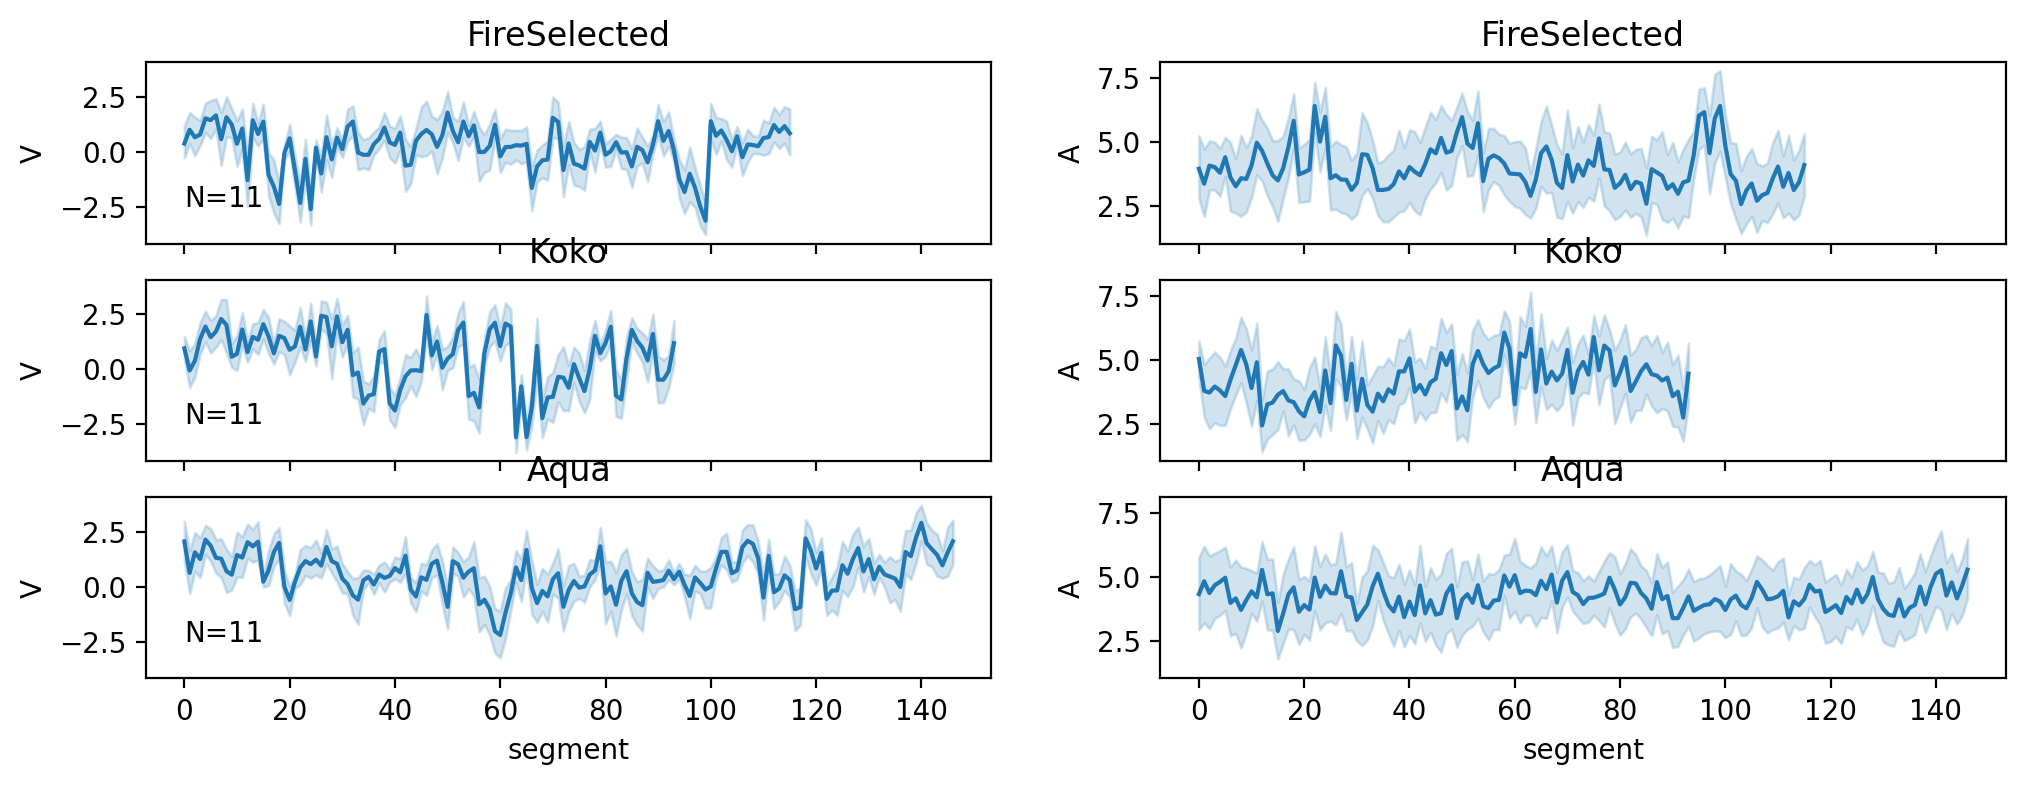

In [21]:
List_stories = ['FireSelected','Koko','Aqua']
fig,axes = plt.subplots(nrows=len(List_stories),ncols=2,figsize=(len(List_stories)*4,4),dpi=200,sharex=True,sharey='col')
for i,story in enumerate(List_stories):
    for j,rating in enumerate(['V','A']):
        ax = axes[i,j]
        df_plot = df_ratings_raw.loc[df_ratings_raw['story']==story].loc[df_ratings_raw['rating']==rating]
        N_subj = df_plot['subid'].unique().shape[0]
        sns.lineplot(data=df_plot,x='segment',y='value',ax=ax).set_title(story)
        ax.set(ylabel=rating)
        if j == 0:
            ax.text(x=0,y=-2.5,s=f'N={N_subj}')
            

In [ ]:
df_ratings_raw = []
for story in ['FireSelected','Koko','Aqua']:
    # ImagineTime
    df = pd.DataFrame(data[[x for x in data.columns if x.startswith(f'rating_{story}_1')]].values)
    df.columns = [f"x{i+1}" for i in range(df.shape[1])]
    df['subid'] = data['ResponseID']
    df['subid_idx'] = data.index
    df['modality'] = story
    df['rating'] = 'ImagineTime'
    df_ratings_raw.append(df)

    # valence-arousal grid
    for var, label in zip(['V','A'],['_x','_y']):
        df = pd.DataFrame(data[[x for x in data.columns if x.startswith(f'Grid_{modality}') and label in x]].values)
        df.columns = [f"x{i+1}" for i in range(df.shape[1])]
        df['subid'] = data['ResponseID']
        df['subid_idx'] = data.index
        df['modality'] = modality
        df['rating'] = var
        df_ratings_raw.append(df)

    # grid RT
    df = pd.DataFrame(data[[x for x in data.columns if x.startswith(f'Grid_timing_{modality}_3')]].values)
    df.columns = [f"x{i+1}" for i in range(df.shape[1])]
    df['subid'] = data['ResponseID']
    df['subid_idx'] = data.index
    df['modality'] = modality
    df['rating'] = 'RT_grid'
    df_ratings_raw.append(df)

    # behavioral ratings
    for var in ['Vividness','Difficulty','Familiarity']:
        df = pd.DataFrame(data[data[[x for x in data.columns if x.startswith(f'{var}_{modality}')]].columns[3:]].values)
        df.columns = [f"x{i+1}" for i in range(df.shape[1])]
        df['subid'] = data['ResponseID']
        df['subid_idx'] = data.index
        df['modality'] = modality
        df['rating'] = var
        df_ratings_raw.append(df)

df_ratings_raw = pd.concat(df_ratings_raw,ignore_index=True)

'Q1'

In [17]:
[x for x in data.columns if 'rating' in x]

['rating_FireSelected_1_x(276)',
 'rating_FireSelected_1_y(276)',
 'rating_FireSelected_1_x(277)',
 'rating_FireSelected_1_y(277)',
 'rating_FireSelected_1_x(278)',
 'rating_FireSelected_1_y(278)',
 'rating_FireSelected_1_x(279)',
 'rating_FireSelected_1_y(279)',
 'rating_FireSelected_1_x(280)',
 'rating_FireSelected_1_y(280)',
 'rating_FireSelected_1_x(281)',
 'rating_FireSelected_1_y(281)',
 'rating_FireSelected_1_x(282)',
 'rating_FireSelected_1_y(282)',
 'rating_FireSelected_1_x(283)',
 'rating_FireSelected_1_y(283)',
 'rating_FireSelected_1_x(284)',
 'rating_FireSelected_1_y(284)',
 'rating_FireSelected_1_x(285)',
 'rating_FireSelected_1_y(285)',
 'rating_FireSelected_1_x(286)',
 'rating_FireSelected_1_y(286)',
 'rating_FireSelected_1_x(287)',
 'rating_FireSelected_1_y(287)',
 'rating_FireSelected_1_x(288)',
 'rating_FireSelected_1_y(288)',
 'rating_FireSelected_1_x(289)',
 'rating_FireSelected_1_y(289)',
 'rating_FireSelected_1_x(290)',
 'rating_FireSelected_1_y(290)',
 'rating_F